In [1]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt

import pickle
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

/home/anya/Documents/uni/data analysis/quantitative-swiftology/LinDa-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Qwen
## Song embeddings

In [2]:
with open('embeddings/qwen_full_song_embeddings.pkl', "rb") as f:
    qwen_full_song_embeddings = pickle.load(f)
dataset = pd.read_csv('.data/dataset_no_reduntant.csv')

In [4]:
pca = PCA(n_components=2)
pca_v = pca.fit_transform(qwen_full_song_embeddings)
print(pca.explained_variance_ratio_)

X_embedded = TSNE(n_components=2, learning_rate='auto',
                  init='random', perplexity=3,
                  random_state=1).fit_transform(qwen_full_song_embeddings)
X_embedded.shape
reducer = umap.UMAP()
embedding_umap = reducer.fit_transform(qwen_full_song_embeddings)

dataset['X_pca'] = pca_v[:, 0]
dataset['Y_pca'] = pca_v[:, 1]

dataset['X_qwen_tsne'] = X_embedded[:, 0]
dataset['Y_qwen_tsne'] = X_embedded[:, 1]

dataset['X_qwen_umap'] = embedding_umap[:, 0]
dataset['Y_qwen_umap'] = embedding_umap[:, 1]

[0.04130517 0.03500105]


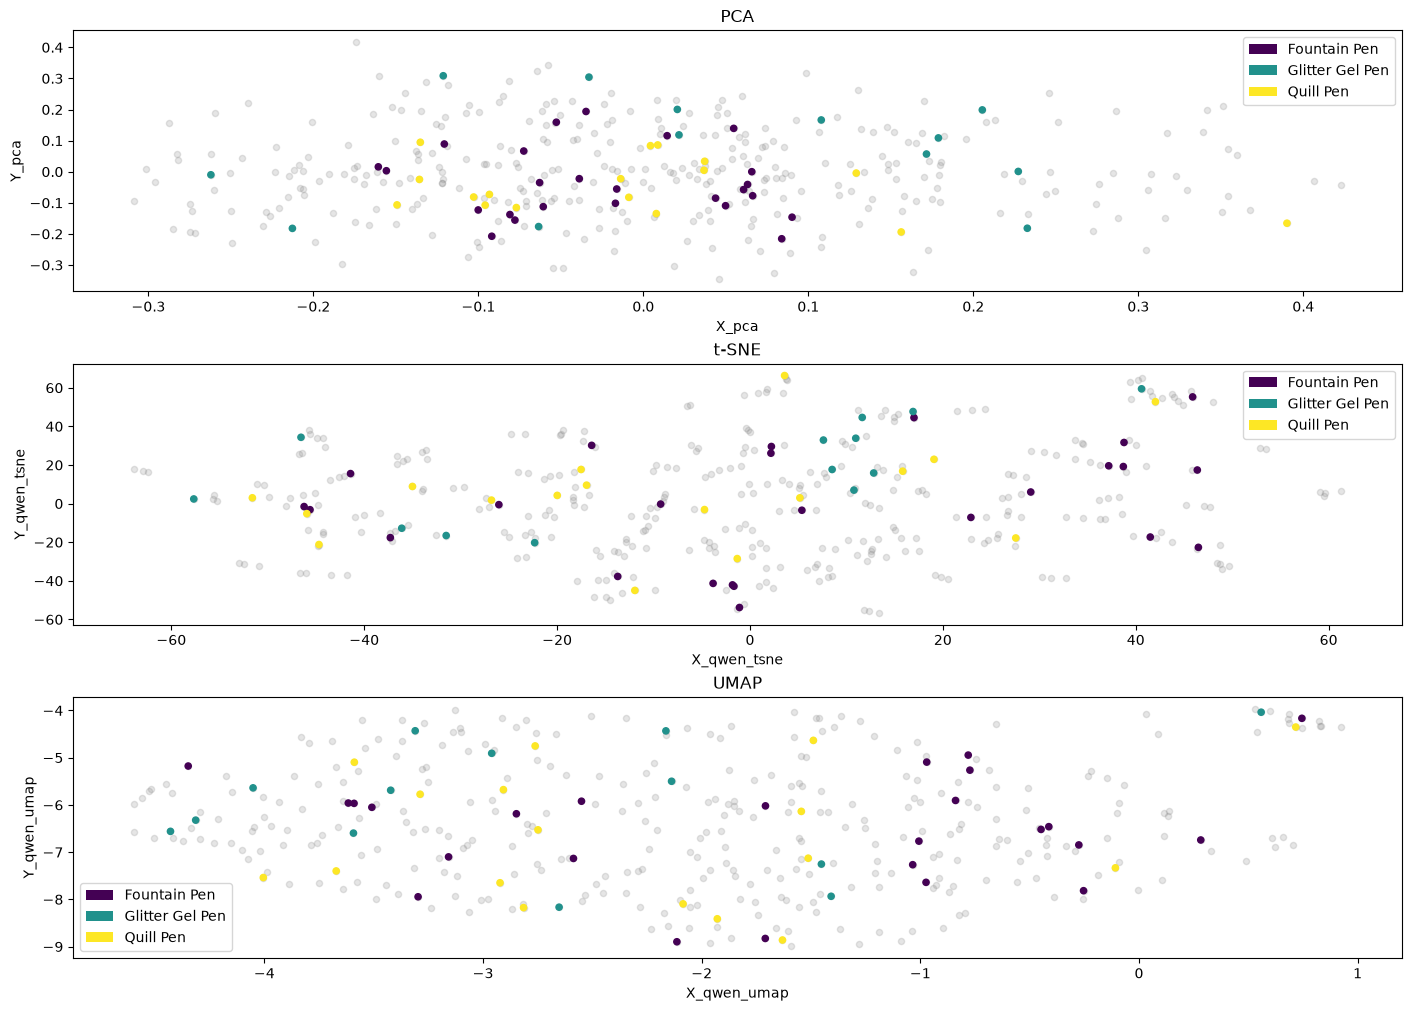

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)


dataset.plot.scatter(x='X_pca', y='Y_pca',
                           c='gray', alpha=0.2, ax=axes[0])
dataset[dataset['Pen Category'].notna()].plot.scatter(x='X_pca', y='Y_pca',
                           c='Pen Category', alpha=1, ax=axes[0])
axes[0].set_title('PCA', loc='center')

dataset.plot.scatter(x='X_qwen_tsne', y='Y_qwen_tsne',
                           c='gray', alpha=0.2, ax=axes[1])
dataset[dataset['Pen Category'].notna()].plot.scatter(x='X_qwen_tsne', y='Y_qwen_tsne',
                           c='Pen Category', alpha=1, ax=axes[1])
axes[1].set_title('t-SNE', loc='center')

dataset.plot.scatter(x='X_qwen_umap', y='Y_qwen_umap',
                           c='gray', alpha=0.2, ax=axes[2])
dataset[dataset['Pen Category'].notna()].plot.scatter(x='X_qwen_umap', y='Y_qwen_umap',
                           c='Pen Category', alpha=1, ax=axes[2])
axes[2].set_title('UMAP', loc='center')

plt.savefig("figures/songs_dimred.png")

In [3]:
def is_liz_in_writers(loc):
    try:
        if 'Liz Rose' in loc:
            return True
        else:
            return False
    except:
        return np.nan

def is_jack_in_writers(loc):
    try:
        if 'Jack Michael Antonoff' in loc:
            return True
        else:
            return False
    except:
        return np.nan
    
def is_aaron_in_writers(loc):
    try:
        if 'Aaron Brooking Dessner' in loc:
            return True
        else:
            return False
    except:
        return np.nan
    
def is_maxmartin_in_writers(loc):
    try:
        if 'Max Martin' in loc:
            return True
        else:
            return False
    except:
        return np.nan
dataset['is_aaron_in_writers'] = dataset.Writers.apply(is_aaron_in_writers)
dataset['is_maxmartin_in_writers'] = dataset.Writers.apply(is_maxmartin_in_writers)
dataset['is_jack_in_writers'] = dataset.Writers.apply(is_jack_in_writers)
dataset['is_liz_in_writers'] = dataset.Writers.apply(is_liz_in_writers)

In [6]:
fig = px.scatter(
    dataset, 
    x="X_qwen_tsne", 
    y="Y_qwen_tsne", 
    color="Pen Category",
    title="Qwen song embeddings",
    hover_name="Song Name"
)

fig.show()

html_str = fig.to_html(full_html=False, include_plotlyjs='cdn')

with open("figures/qwen_song_categories.html", "w") as f:
    f.write(html_str)

In [8]:
fig = px.scatter(
    dataset[dataset['Release Year'].notna()], 
    x="X_qwen_tsne", 
    y="Y_qwen_tsne", 
    color="Release Year",
    title="Qwen song embeddings",
    hover_name="Song Name"
)

fig.show()

In [16]:
fig = px.scatter(
    dataset, 
    x="X_qwen_tsne", 
    y="Y_qwen_tsne", 
    color="is_aaron_in_writers",
    title="Qwen song embeddings",
    hover_name="Song Name"
)

fig.show()

html_str = fig.to_html(full_html=False, include_plotlyjs='cdn')

with open("figures/qwen_song_is_aaron_in_writers.html", "w") as f:
    f.write(html_str)

In [18]:
fig = px.scatter(
    dataset, 
    x="X_qwen_tsne", 
    y="Y_qwen_tsne", 
    color="Album",
    title="Qwen song embeddings",
    hover_name="Song Name"
)

fig.show()

html_str = fig.to_html(full_html=False, include_plotlyjs='cdn')

with open("figures/qwen_song_Album.html", "w") as f:
    f.write(html_str)

## Line embeddings

In [5]:
# with open('embeddings/qwen_list_lyrics_embeddings.pkl', "rb") as f:
#     qwen_list_lyrics_embeddings = pickle.load(f)

# pca = PCA(n_components=2)
# pca_v = pca.fit_transform(qwen_list_lyrics_embeddings)
# print(pca.explained_variance_ratio_)

# X_embedded = TSNE(n_components=2, learning_rate='auto',
#                   init='random', perplexity=3,
#                   random_state=1).fit_transform(qwen_list_lyrics_embeddings)
X_embedded.shape
reducer = umap.UMAP()
embedding_umap = reducer.fit_transform(qwen_list_lyrics_embeddings)

song_names = []
writers = []
albums = []
years = []
is_aaron_in_writers = []
is_maxmartin_in_writers = []
pen_categories = []
is_jack_in_writers = []
is_liz_in_writers = []
lines = []
for song_i in range(dataset.shape[0]):
    for line in dataset.Lyrics_no_redundant.iloc[song_i].split('\n'):
        lines.append(line)
        song_names.append(dataset.iloc[song_i]['Song Name'])
        writers.append(dataset.iloc[song_i]['Writers'])
        albums.append(dataset.iloc[song_i]['Album'])
        years.append(dataset.iloc[song_i]['Release Year'])
        is_aaron_in_writers.append(dataset.iloc[song_i]['is_aaron_in_writers'])
        is_maxmartin_in_writers.append(dataset.iloc[song_i]['is_maxmartin_in_writers'])
        is_jack_in_writers.append(dataset.iloc[song_i]['is_jack_in_writers'])
        is_liz_in_writers.append(dataset.iloc[song_i]['is_liz_in_writers'])
        pen_categories.append(dataset.iloc[song_i]['Pen Category'])

dataset_lines = pd.DataFrame({
    'Line': lines,
    'Song Name': song_names,
    'Writers': writers,
    'Album': albums,
    'Release Year': years,
    'Pen Category': pen_categories,
    'is_aaron_in_writers': is_aaron_in_writers,
    'is_maxmartin_in_writers': is_maxmartin_in_writers,
    'is_jack_in_writers': is_jack_in_writers,
    'is_liz_in_writers': is_liz_in_writers,
    'X_qwen_pca': pca_v[:, 0],
    'Y_qwen_pca': pca_v[:, 1],
    'X_qwen_tsne': X_embedded[:, 0],
    'Y_qwen_tsne': X_embedded[:, 1],
    'X_qwen_umap': embedding_umap[:, 0],
    'Y_qwen_umap': embedding_umap[:, 1],
})
dataset_lines.head()

,Line,Song Name,Writers,Album,Release Year,Pen Category,is_aaron_in_writers,is_maxmartin_in_writers,is_jack_in_writers,is_liz_in_writers,X_qwen_pca,Y_qwen_pca,X_qwen_tsne,Y_qwen_tsne,X_qwen_umap,Y_qwen_umap
0,I was in my new house placing daydreams,Cassandra,"['Aaron Brooking Dessner', ' Taylor Alison Swi...",THE TORTURED POETS DEPARTMENT,2024.0,NaN,True,False,False,False,0.226401,0.067730,13.100697,-80.373604,9.213599,-1.233998
1,Patching up the crack along the wall,Cassandra,"['Aaron Brooking Dessner', ' Taylor Alison Swi...",THE TORTURED POETS DEPARTMENT,2024.0,NaN,True,False,False,False,-0.054932,-0.233329,-6.610951,-49.176926,8.130181,-1.298203
2,I pass it and lose track of what I'm saying,Cassandra,"['Aaron Brooking Dessner', ' Taylor Alison Swi...",THE TORTURED POETS DEPARTMENT,2024.0,NaN,True,False,False,False,0.082846,0.132046,72.651192,8.178046,10.495952,2.232779
3,'Cause that's where I was when I got the call,Cassandra,"['Aaron Brooking Dessner', ' Taylor Alison Swi...",THE TORTURED POETS DEPARTMENT,2024.0,NaN,True,False,False,False,0.164992,0.212995,69.572006,-24.111660,11.623530,2.373920
4,When the first stone's thrown there's screamin',Cassandra,"['Aaron Brooking Dessner', ' Taylor Alison Swi...",THE TORTURED POETS DEPARTMENT,2024.0,NaN,True,False,False,False,-0.091921,-0.190622,-26.678804,-26.453022,8.191622,-1.481668


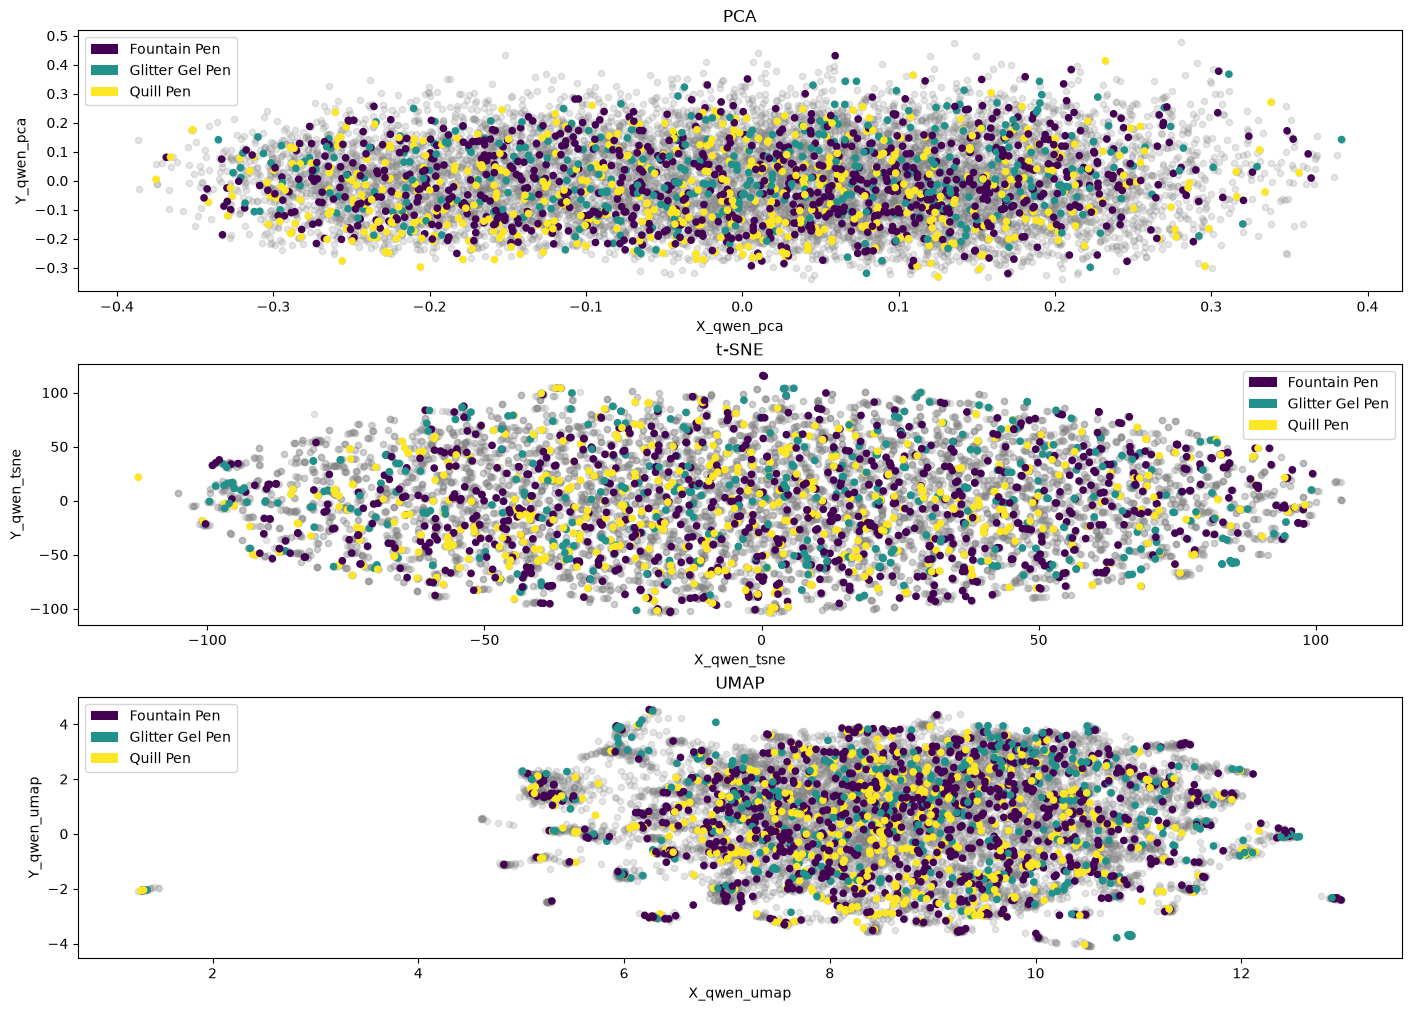

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)


dataset_lines.plot.scatter(x='X_qwen_pca', y='Y_qwen_pca',
                           c='gray', alpha=0.2, ax=axes[0])
dataset_lines[dataset_lines['Pen Category'].notna()].plot.scatter(x='X_qwen_pca', y='Y_qwen_pca',
                           c='Pen Category', alpha=1, ax=axes[0])
axes[0].set_title('PCA', loc='center')

dataset_lines.plot.scatter(x='X_qwen_tsne', y='Y_qwen_tsne',
                           c='gray', alpha=0.2, ax=axes[1])
dataset_lines[dataset_lines['Pen Category'].notna()].plot.scatter(x='X_qwen_tsne', y='Y_qwen_tsne',
                           c='Pen Category', alpha=1, ax=axes[1])
axes[1].set_title('t-SNE', loc='center')

dataset_lines.plot.scatter(x='X_qwen_umap', y='Y_qwen_umap',
                           c='gray', alpha=0.2, ax=axes[2])
dataset_lines[dataset_lines['Pen Category'].notna()].plot.scatter(x='X_qwen_umap', y='Y_qwen_umap',
                           c='Pen Category', alpha=1, ax=axes[2])
axes[2].set_title('UMAP', loc='center')

plt.savefig("figures/lines_dimred.png")

In [9]:
fig = px.scatter(
    dataset_lines, 
    x="X_qwen_umap", 
    y="Y_qwen_umap", 
    color="Pen Category",
    title="Qwen line embeddings",
    hover_name="Line",
    render_mode="svg"
)

fig.show()

html_str = fig.to_html(full_html=False, include_plotlyjs='cdn')

with open("figures/qwen_lines_pen.html", "w") as f:
    f.write(html_str)

In [10]:
fig = px.scatter(
    dataset_lines, 
    x="X_qwen_umap", 
    y="Y_qwen_umap", 
    color="Album",
    title="Qwen line embeddings",
    hover_name="Line",
    render_mode="svg"
)

fig.show()

# html_str = fig.to_html(full_html=False, include_plotlyjs='cdn')

# with open("figures/qwen_lines_pen.html", "w") as f:
#     f.write(html_str)

In [13]:
fig = px.scatter(
    dataset_lines, 
    x="X_qwen_umap", 
    y="Y_qwen_umap", 
    color="is_jack_in_writers",
    title="Qwen line embeddings",
    hover_name="Line",
    render_mode="svg"
)

fig.show()

# html_str = fig.to_html(full_html=False, include_plotlyjs='cdn')

# with open("figures/qwen_lines_pen.html", "w") as f:
#     f.write(html_str)